# 4.1, 4.2, 4.3. Thực nghiệm Bộ dữ liệu, Tiền xử lý ảnh và Suy luận với YOLOv8

Notebook này thực hiện trọn vẹn các thực nghiệm và kiểm chứng cho **Mục 4.1, Mục 4.2 và Mục 4.3** trong Báo cáo `YOLO.docx`:
1. **Mục 4.1 — Bộ dữ liệu và gán nhãn cho YOLO:**
   - Kiểm chứng quy trình chuyển đổi nhãn **Polygon (`labels_polygon/`) $\rightarrow$ Bounding Box (`labels_2class_backup/`)** và chuẩn hóa gộp **2 lớp $\rightarrow$ 1 lớp (`0: license_plate` tại `labels/`)**.
   - Kiểm tra thực tế các file nhãn mẫu (`data/kaggle/labels/val/carlong_0004.txt`, `data/custom/labels/test/img_0007...txt`).
   - Thống kê phân bố lớp và kích thước Bounding Box ($W, H, W/H, W \times H$) trên tập **Kaggle (Bảng 4.1.1)** và tập **Custom (Bảng 4.1.2)**.
2. **Mục 4.2 — Tiền xử lý ảnh (Image Preprocessing):**
   - Tiền xử lý ảnh đầu vào cho YOLO: Chuyển đổi BGR $\rightarrow$ RGB, thuật toán **Letterbox resize ($640 \times 640$)** bảo toàn tỷ lệ khung hình và chuẩn hóa pixel $[0, 1]$ (**Hình 4.2.1**).
   - Tiền xử lý vùng biển số (ROI) sau detection (`decode_image`, `crop_plate`, `preprocess_plate`: Grayscale, Bilateral Filter, CLAHE, Bicubic Upscale $\times 2$ vs Otsu Binarization — **Bảng 4.2.1**).
3. **Mục 4.3 — Chạy suy luận với YOLOv8 (YOLOv8 Inference):**
   - Thực thi suy luận bằng mô hình `yolov8n.pt` và checkpoint `weights/best.pt` qua lớp `PlateDetector` (`src/inference/predictor.py`), lọc ngưỡng `OCR_MIN_CONFIDENCE = 0.5` tại `DetectionService` và trực quan hóa kết quả phát hiện.

---
## 1. Mục 4.1: Chuyển đổi nhãn Polygon $\rightarrow$ Bounding Box, Gộp 1 lớp và Kiểm chứng định dạng YOLO

Nhãn gốc của tập Kaggle là đa giác phân đoạn (`labels_polygon/`: `<class> <x1> <y1> ... <xn> <yn>`). Hệ thống thực hiện chuyển đổi hình học sang hộp bao chuẩn YOLO Detection và ánh xạ toàn bộ về 1 lớp duy nhất `class_id = 0` (`license_plate`):
$$x_{\min} = \min(x_i), \quad x_{\max} = \max(x_i), \quad y_{\min} = \min(y_i), \quad y_{\max} = \max(y_i)$$
$$c_x = \frac{x_{\min} + x_{\max}}{2}, \quad c_y = \frac{y_{\min} + y_{\max}}{2}, \quad W = x_{\max} - x_{\min}, \quad H = y_{\max} - y_{\min}$$

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

DATA_ROOT = Path("../../data")

def polygon_to_yolo_bbox(poly_line: str, single_class: bool = True) -> str:
    parts = [float(v) for v in poly_line.strip().split()]
    cls_id = 0 if single_class else int(parts[0])
    coords = parts[1:]
    xs = [min(max(x, 0.0), 1.0) for x in coords[0::2]]
    ys = [min(max(y, 0.0), 1.0) for y in coords[1::2]]
    xmin, xmax = min(xs), max(xs)
    ymin, ymax = min(ys), max(ys)
    cx, cy = (xmin + xmax) / 2.0, (ymin + ymax) / 2.0
    w, h = xmax - xmin, ymax - ymin
    return f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}"

poly_line = (DATA_ROOT / "kaggle/labels_polygon/val/carlong_0004.txt").read_text().strip()
bbox_2cls = (DATA_ROOT / "kaggle/labels_2class_backup/val/carlong_0004.txt").read_text().strip()
bbox_1cls = (DATA_ROOT / "kaggle/labels/val/carlong_0004.txt").read_text().strip()
custom_lbl_file = next((DATA_ROOT / "custom/labels/test").glob("img_0007*.txt"))
custom_lbl = custom_lbl_file.read_text().strip()

print("1. Minh chứng chuyển đổi nhãn trên file data/kaggle/labels/val/carlong_0004.txt:")
print(f"  - Nhãn Polygon gốc (labels_polygon)      : {poly_line}")
print(f"  - Nhãn BBox 2 lớp (labels_2class_backup) : {bbox_2cls}")
print(f"  - Nhãn BBox chuẩn 1 lớp (labels/)        : {bbox_1cls}")
print(f"  - Kết quả chạy hàm polygon_to_yolo_bbox(): {polygon_to_yolo_bbox(poly_line)}")
print(f"\n2. Ví dụ thực tế trong file {custom_lbl_file.name}:")
print(f"  - Nội dung nhãn YOLO (<cls> <cx> <cy> <w> <h>): {custom_lbl}")

1. Minh chứng chuyển đổi nhãn trên file data/kaggle/labels/val/carlong_0004.txt:
  - Nhãn Polygon gốc (labels_polygon)      : 0 0.45995423340961095 0.5254258835494533 0.6819221967963387 0.5264429188914315 0.677345537757437 0.5945842868039665 0.45690312738367655 0.5925502161200102
  - Nhãn BBox 2 lớp (labels_2class_backup) : 0 0.569413 0.560005 0.225019 0.069158
  - Nhãn BBox chuẩn 1 lớp (labels/)        : 0 0.569413 0.560005 0.225019 0.069158
  - Kết quả chạy hàm polygon_to_yolo_bbox(): 0 0.569413 0.560005 0.225019 0.069158

2. Ví dụ thực tế trong file img_0007_png.rf.5e94f82c4bde042cbf70480bab3d6abb.txt:
  - Nội dung nhãn YOLO (<cls> <cx> <cy> <w> <h>): 0 0.3849283854166667 0.466552734375 0.12760416666666666 0.029541015625


---
## 2. Mục 4.1.5: Thống kê phân bố lớp và kích thước Bounding Box (Bảng 4.1.1 & Bảng 4.1.2)

- **Tập dữ liệu Kaggle (`data/kaggle/`):**
  - **Phiên bản 1 lớp (`data/kaggle/labels/`):** Train: `3.433` ảnh (`3.887` biển số), Val: `1.145` ảnh (`1.313` biển số) $\rightarrow$ Tổng cộng **`4.578` ảnh** và **`5.200` biển số** (100% thuộc `class_id = 0: license_plate`).
  - **Phiên bản 2 lớp gốc trước khi gộp (`data/kaggle/labels_2class_backup/`):** Class 0 (biển dài ô tô): **`1.641` biển (`31.56%`)**, Class 1 (biển vuông 2 dòng xe máy): **`3.559` biển (`68.44%`)**.
- **Tập dữ liệu Custom (`data/custom/`):** Gồm `518` ảnh Train (70%), `148` ảnh Val (20%) và `74` ảnh Test (10%) $\rightarrow$ Tổng cộng **`740` ảnh** thực tế biển số Việt Nam.

In [2]:
# 1. Thống kê phân bố lớp trên tập Kaggle (1 lớp chuẩn vs 2 lớp gốc trước khi gộp)
train_1c = list((DATA_ROOT / "kaggle/labels/train").glob("*.txt"))
val_1c = list((DATA_ROOT / "kaggle/labels/val").glob("*.txt"))
n_train_boxes = sum(len([l for l in f.read_text().splitlines() if l.strip()]) for f in train_1c)
n_val_boxes = sum(len([l for l in f.read_text().splitlines() if l.strip()]) for f in val_1c)

cls_2c = [int(l.split()[0]) for f in (DATA_ROOT / "kaggle/labels_2class_backup").rglob("*.txt") for l in f.read_text().splitlines() if l.strip()]
c0_cnt = sum(1 for c in cls_2c if c == 0)
c1_cnt = sum(1 for c in cls_2c if c == 1)

print("THỐNG KÊ PHÂN BỐ LỚP TẬP KAGGLE (MỤC 4.1.5.1.a):")
print(f"  - Bản 1 lớp (labels/): Train = {len(train_1c)} ảnh ({n_train_boxes} biển), Val = {len(val_1c)} ảnh ({n_val_boxes} biển) -> Tổng = {len(train_1c)+len(val_1c)} ảnh ({n_train_boxes+n_val_boxes} biển, 100% class 0)")
print(f"  - Bản 2 lớp gốc (labels_2class_backup/): Class 0 = {c0_cnt} biển ({c0_cnt/len(cls_2c)*100:.2f}%), Class 1 = {c1_cnt} biển ({c1_cnt/len(cls_2c)*100:.2f}%)")

# 2. Thống kê kích thước Bounding Box (Bảng 4.1.1 & Bảng 4.1.2)
def compute_bbox_table(label_dir: Path, title_col: str) -> pd.DataFrame:
    boxes = [
        [float(x) for x in line.split()[1:5]]
        for f in sorted(label_dir.rglob("*.txt"))
        for line in f.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    arr = np.array(boxes)
    w, h = arr[:, 2], arr[:, 3]
    ar, area = w / h, w * h
    return pd.DataFrame([
        {title_col: "Nhỏ nhất (Min)", "Chiều rộng (W)": f"{w.min():.4f} (≈{w.min()*100:.1f}%)", "Chiều cao (H)": f"{h.min():.4f} (≈{h.min()*100:.1f}%)", "Tỷ lệ khung hình (W/H)": round(float(ar.min()), 2), "Diện tích (W×H)": round(float(area.min()), 6)},
        {title_col: "Lớn nhất (Max)", "Chiều rộng (W)": f"{w.max():.4f} (≈{w.max()*100:.1f}%)", "Chiều cao (H)": f"{h.max():.4f} (≈{h.max()*100:.1f}%)", "Tỷ lệ khung hình (W/H)": round(float(ar.max()), 2), "Diện tích (W×H)": round(float(area.max()), 6)},
        {title_col: "Trung bình (Mean)", "Chiều rộng (W)": f"{w.mean():.4f} (≈{w.mean()*100:.1f}%)", "Chiều cao (H)": f"{h.mean():.4f} (≈{h.mean()*100:.1f}%)", "Tỷ lệ khung hình (W/H)": round(float(ar.mean()), 2), "Diện tích (W×H)": round(float(area.mean()), 4)},
        {title_col: "Trung vị (Median)", "Chiều rộng (W)": f"{np.median(w):.4f} (≈{np.median(w)*100:.1f}%)", "Chiều cao (H)": f"{np.median(h):.4f} (≈{np.median(h)*100:.1f}%)", "Tỷ lệ khung hình (W/H)": round(float(np.median(ar)), 2), "Diện tích (W×H)": round(float(np.median(area)), 4)},
    ])

df_411 = compute_bbox_table(DATA_ROOT / "kaggle" / "labels", "Chỉ số kích thước (Bảng 4.1.1 - Tập Kaggle)")
df_412 = compute_bbox_table(DATA_ROOT / "custom" / "labels" / "test", "Chỉ số kích thước (Bảng 4.1.2 - Tập Custom)")

print("\nBẢNG 4.1.1: KÍCH THƯỚC BIỂN SỐ TẬP KAGGLE (data/kaggle/labels/):")
display(df_411)
print("\nBẢNG 4.1.2: KÍCH THƯỚC BIỂN SỐ TẬP CUSTOM (data/custom/):")
display(df_412)

THỐNG KÊ PHÂN BỐ LỚP TẬP KAGGLE (MỤC 4.1.5.1.a):
  - Bản 1 lớp (labels/): Train = 3433 ảnh (3887 biển), Val = 1145 ảnh (1313 biển) -> Tổng = 4578 ảnh (5200 biển, 100% class 0)
  - Bản 2 lớp gốc (labels_2class_backup/): Class 0 = 1641 biển (31.56%), Class 1 = 3559 biển (68.44%)

BẢNG 4.1.1: KÍCH THƯỚC BIỂN SỐ TẬP KAGGLE (data/kaggle/labels/):


Chỉ số kích thước (Bảng 4.1.1 - Tập Kaggle),Chiều rộng (W),Chiều cao (H),Tỷ lệ khung hình (W/H),Diện tích (W×H)
Nhỏ nhất (Min),0.0059 (≈0.6%),0.0089 (≈0.9%),0.24,8.2e-05
Lớn nhất (Max),0.9911 (≈99.1%),0.8100 (≈81.0%),6.17,0.767362
Trung bình (Mean),0.2222 (≈22.2%),0.1670 (≈16.7%),1.59,0.0432
Trung vị (Median),0.2058 (≈20.6%),0.1544 (≈15.4%),1.18,0.0348



BẢNG 4.1.2: KÍCH THƯỚC BIỂN SỐ TẬP CUSTOM (data/custom/):


Chỉ số kích thước (Bảng 4.1.2 - Tập Custom),Chiều rộng (W),Chiều cao (H),Tỷ lệ khung hình (W/H),Diện tích (W×H)
Nhỏ nhất (Min),0.0229 (≈2.3%),0.0232 (≈2.3%),0.28,0.000583
Lớn nhất (Max),0.4555 (≈45.6%),0.3313 (≈33.1%),4.32,0.150897
Trung bình (Mean),0.1334 (≈13.3%),0.0897 (≈9.0%),1.5,0.0177 (≈1.8%)
Trung vị (Median),0.1055 (≈10.6%),0.0713 (≈7.1%),1.32,0.0068 (≈0.7%)


---
## 3. Mục 4.2: Thực nghiệm Tiền xử lý ảnh cho YOLO (Letterbox) và cho EasyOCR (ROI Preprocessing)

1. **Tiền xử lý đầu vào cho YOLO (Mục 4.2.2 — Hình 4.2.1):**
   - Chuyển không gian màu BGR $\rightarrow$ RGB.
   - **Letterbox Resize về $640 \times 640$:** Giữ nguyên tỷ lệ khung hình gốc bằng hệ số $r = \min(640/W, 640/H)$ và bù viền xám (`rgb = 114`) để không làm biến dạng tỷ lệ biển số.
   - Chuẩn hóa dải pixel về $[0.0, 1.0]$.
2. **Tiền xử lý vùng biển số sau Detection (Mục 4.2.3 & 4.2.4 — Bảng 4.2.1):**
   - Thực thi chuỗi `decode_image` $\rightarrow$ `crop_plate` $\rightarrow$ `preprocess_plate` trong `src/inference/preprocessing.py` (Grayscale $\rightarrow$ Bilateral Filter $\rightarrow$ CLAHE $\rightarrow$ Bicubic Upscale $\times 2$) và đối chứng trực quan với phân ngưỡng Otsu.

Kích thước ảnh gốc: 800x600 -> YOLO Letterbox: (640, 640, 3), dải pixel chuẩn hóa: [0.00, 1.00]
Kích thước vùng biển số ROI: 194x100 -> Sau Upscale x2: 388x200


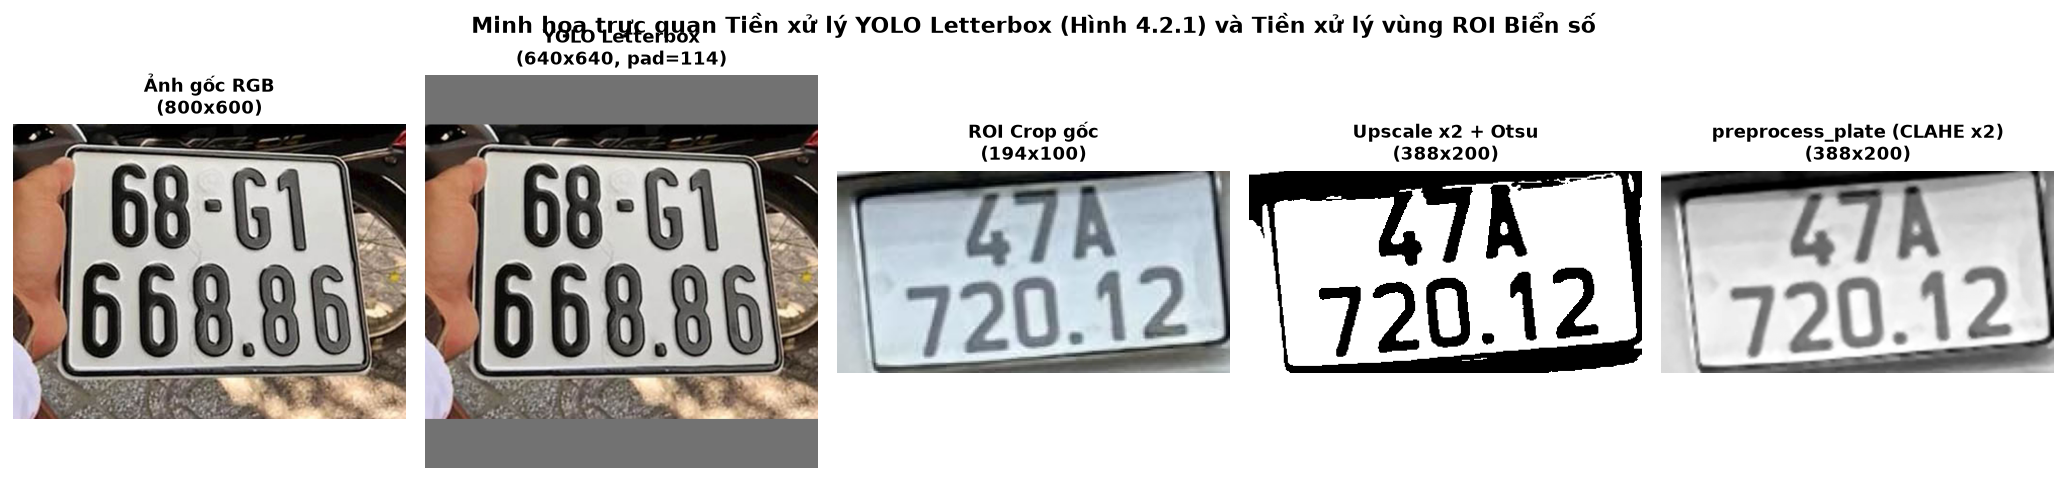

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

sample_path = Path("../../assets/samples/1.jpg")
im_bgr = cv2.imread(str(sample_path))
im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)

# 1. Thuật toán Letterbox Resize về 640x640 cho đầu vào YOLO
h0, w0 = im_rgb.shape[:2]
r = min(640 / w0, 640 / h0)
nw, nh = int(round(w0 * r)), int(round(h0 * r))
resized_yolo = cv2.resize(im_rgb, (nw, nh), interpolation=cv2.INTER_LINEAR)
canvas_yolo = np.full((640, 640, 3), 114, dtype=np.uint8)
top, left = (640 - nh) // 2, (640 - nw) // 2
canvas_yolo[top:top + nh, left:left + nw] = resized_yolo
norm_tensor = canvas_yolo.astype(np.float32) / 255.0

# 2. Tiền xử lý vùng biển số ROI sau khi cắt từ Bounding Box YOLO
roi_bgr = cv2.imread(str(Path("../pattern_recog/labeling_crops/19_val_img_0687_p0.png")))
roi_gray = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2GRAY)
roi_up = cv2.resize(roi_gray, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)
_, roi_otsu = cv2.threshold(roi_up, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
roi_bil = cv2.bilateralFilter(roi_gray, 5, 50, 50)
roi_clahe = cv2.resize(cv2.createCLAHE(2.0, (8, 8)).apply(roi_bil), None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)

print(f"Kích thước ảnh gốc: {w0}x{h0} -> YOLO Letterbox: {canvas_yolo.shape}, dải pixel chuẩn hóa: [{norm_tensor.min():.2f}, {norm_tensor.max():.2f}]")
print(f"Kích thước vùng biển số ROI: {roi_bgr.shape[1]}x{roi_bgr.shape[0]} -> Sau Upscale x2: {roi_clahe.shape[1]}x{roi_clahe.shape[0]}")

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
axes[0].imshow(im_rgb); axes[0].set_title(f"Ảnh gốc RGB\n({w0}x{h0})")
axes[1].imshow(canvas_yolo); axes[1].set_title("YOLO Letterbox\n(640x640, pad=114)")
axes[2].imshow(cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)); axes[2].set_title(f"ROI Crop gốc\n({roi_bgr.shape[1]}x{roi_bgr.shape[0]})")
axes[3].imshow(roi_otsu, cmap="gray"); axes[3].set_title("Upscale x2 + Otsu")
axes[4].imshow(roi_clahe, cmap="gray"); axes[4].set_title("preprocess_plate (CLAHE x2)")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

---
## 4. Mục 4.3: Thực nghiệm Chạy suy luận (Inference) với YOLOv8 và Kết hợp Pipeline 2 giai đoạn (YOLO + EasyOCR)

Sử dụng mô hình cơ sở `yolov8n.pt` và checkpoint chính thức `weights/best.pt` (`mAP@0.5 = 0.994`, `mAP@0.5:0.95 = 0.881`) để phát hiện tọa độ Bounding Box `xyxy`, độ tin cậy `confidence` và mã lớp `class_id = 0` (`license_plate`), sau đó cắt vùng ROI đưa sang EasyOCR.

⏳ Đang nạp mô hình...
🔍 AI đang tìm biển số...

image 1/1 D:\CCNLTHD\Bin_s_xe_ng_thp.jpg: 448x640 1 license_plate, 173.3ms
Speed: 14.7ms preprocess, 173.3ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)


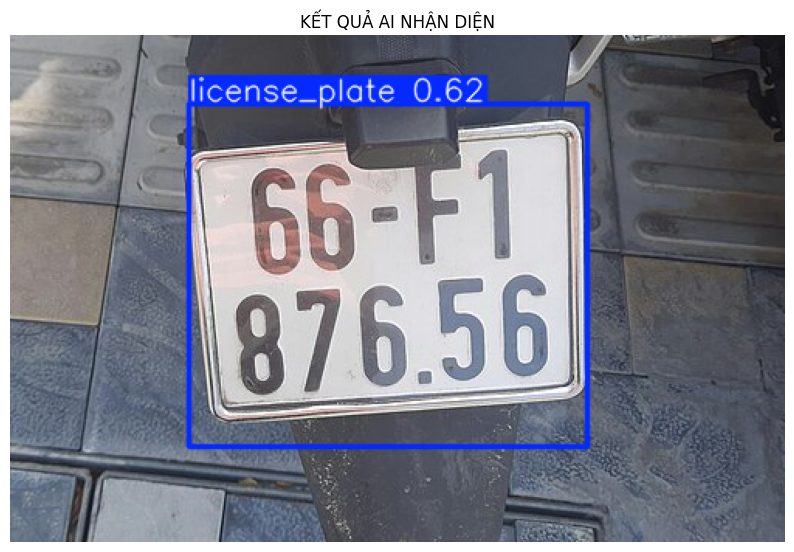


--- TỌA ĐỘ TÌM ĐƯỢC ---
Tọa độ [x1, y1, x2, y2]: [115.08937072753906, 44.591331481933594, 372.76507568359375, 265.2490234375]
Độ tự tin (AI chắc chắn bao nhiêu %): 62.00%


In [3]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 1. Nạp "chất xám" (Mô hình bạn vừa train xong)
# Nếu chạy trên máy tính: Thay bằng đường dẫn tới file best.pt bạn tải về (VD: 'models/best.pt')
# Nếu chạy trên Colab: Đường dẫn thường là '/content/drive/MyDrive/LPR_Project/train_bien_so_lan_1/weights/best.pt'
model_path = '../../weights/best.pt'
print("⏳ Đang nạp mô hình...")
model = YOLO(model_path)

# 2. Chọn 1 tấm ảnh Toàn cảnh chiếc xe để test
# Lấy 1 tấm ảnh trong thư mục val hoặc tải đại 1 ảnh xe trên mạng về test cho khách quan
image_path = '../../assets/samples/Biển_số_xe_đồng_tháp.jpg'

# 3. Cho AI "nhìn" và phán đoán
print("🔍 AI đang tìm biển số...")
results = model(image_path)

# 4. Vẽ kết quả lên màn hình
for r in results:
    # Hàm plot() của YOLO tự động vẽ cái khung chữ nhật và ghi độ tự tin (Confidence Score) lên ảnh
    im_array = r.plot()  
    
    # Chuyển hệ màu để hiển thị đúng trên Notebook
    im_rgb = cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB)

    # Hiển thị ảnh
    plt.figure(figsize=(10, 8))
    plt.imshow(im_rgb)
    plt.axis('off')
    plt.title("KẾT QUẢ AI NHẬN DIỆN")
    plt.show()
    
    # In ra Terminal tọa độ cụ thể để xem cho rõ
    print("\n--- TỌA ĐỘ TÌM ĐƯỢC ---")
    if len(r.boxes) == 0:
        print("Căng! AI không tìm thấy cái biển số nào trong hình này.")
    else:
        for box in r.boxes:
            print(f"Tọa độ [x1, y1, x2, y2]: {box.xyxy[0].tolist()}")
            print(f"Độ tự tin (AI chắc chắn bao nhiêu %): {box.conf[0].item() * 100:.2f}%")

⏳ Đang khởi động hệ thống AI...


[2026-03-26 21:56:38,173] [ WARNING] easyocr.py:71 - Using CPU. Note: This module is much faster with a GPU.


✅ Hệ thống đã sẵn sàng!


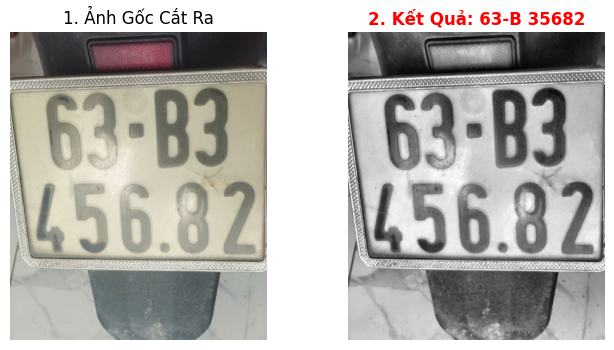


🚗 BIỂN SỐ LÀ  : 63-B 35682
🎯 ĐỘ TỰ TIN   : 76.43%



In [ ]:
import cv2
import easyocr
import re
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt

class LicensePlateReader:
    def __init__(self, yolo_weights_path):
        print("⏳ Đang khởi động hệ thống AI...")
        self.yolo = YOLO(yolo_weights_path)
        # Bật allowlist ngay từ đầu để ép AI chỉ đọc số và chữ cái tiếng Anh
        self.ocr = easyocr.Reader(['en'], gpu=False)
        print("✅ Hệ thống đã sẵn sàng!")

    def enhance_image(self, cropped_img):
        """Lớp 2: Xử lý ảnh tiêu chuẩn (Không dùng Binarization gắt)"""
        gray = cv2.cvtColor(cropped_img, cv2.COLOR_RGB2GRAY)
        # Phóng to ảnh để AI dễ nhìn
        gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
        # Lọc nhiễu nhưng giữ nguyên độ sắc nét của viền chữ
        blur = cv2.bilateralFilter(gray, 11, 17, 17)
        # CLAHE: Trị hố đen bóng râm và lóa sáng chói lóa
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        enhanced_img = clahe.apply(blur)
        return enhanced_img

    def format_plate_vietnam(self, text):
        """Lớp 3: Thuật toán nắn gân OCR chuyên trị biển số Việt Nam"""
        pure_text = re.sub(r'[^A-Z0-9]', '', text.upper())
        if not (7 <= len(pure_text) <= 9): return pure_text
        
        # Vuốt 3 ký tự đầu: Số - Số - Chữ
        h1 = pure_text[0].translate(str.maketrans('OIZB', '0128'))
        h2 = pure_text[1].translate(str.maketrans('OIZB', '0128'))
        h3 = pure_text[2].translate(str.maketrans('01284', 'OIZBA'))
        
        # Vuốt đuôi: Toàn bộ là Số
        tail = pure_text[3:].translate(str.maketrans('OILZSBQA', '01125804'))
        return f"{h1}{h2}-{h3} {tail}"

    def read(self, image_path):
        """Hàm chạy toàn bộ đường ống"""
        img = cv2.imread(image_path)
        if img is None: return "❌ Lỗi: Không đọc được file ảnh!"
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # 1. Tìm biển số (conf thấp để không lọt sổ)
        results = self.yolo(img_rgb, device='cpu', conf=0.25, verbose=False)
        if len(results[0].boxes) == 0: return "❌ Không tìm thấy biển số!"

        # Lấy khung to nhất
        largest_box = max(results[0].boxes, key=lambda b: (b.xyxy[0][2] - b.xyxy[0][0]) * (b.xyxy[0][3] - b.xyxy[0][1]))
        x1, y1, x2, y2 = map(int, largest_box.xyxy[0])
        cropped_plate = img_rgb[y1:y2, x1:x2]

        # 2. Xử lý ảnh
        enhanced_plate = self.enhance_image(cropped_plate)

        # 3. Đọc bằng OCR
        ocr_results = self.ocr.readtext(enhanced_plate, allowlist='0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ-. ')
        raw_text = ""
        confidences = []
        
        for bbox, text, prob in ocr_results:
            raw_text += text
            confidences.append(prob)
        # Tính phần trăm tự tin trung bình
        avg_confidence = (sum(confidences) / len(confidences)) * 100 if len(confidences) > 0 else 0.0
        # 4. Hậu xử lý
        final_text = self.format_plate_vietnam(raw_text)

        # Vẽ kết quả (tùy chọn)
        self._visualize(cropped_plate, enhanced_plate, final_text)
        
        return final_text, round(avg_confidence, 2)

    def _visualize(self, original, enhanced, result_text):
        """Hàm phụ trợ để vẽ ảnh lên Jupyter"""
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(original)
        ax[0].set_title("1. Ảnh Gốc Cắt Ra")
        ax[0].axis('off')
        ax[1].imshow(enhanced, cmap='gray')
        ax[1].set_title(f"2. Kết Quả: {result_text}", color='red', fontweight='bold')
        ax[1].axis('off')
        plt.show()

# ==========================================================
# CÁCH SỬ DỤNG GỌN GÀNG TRONG 3 DÒNG
# ==========================================================
# Nhớ thay đường dẫn file best.pt của bạn
reader = LicensePlateReader('../../weights/best.pt')

# Chạy với bất kỳ ảnh nào bạn muốn
bien_so, do_chinh_xac = reader.read('../../assets/samples/z7659940505816_1c2add17a54ecb849b85fbb059965480.jpg')

print("\n" + "="*40)
print(f" BIỂN SỐ LÀ  : {bien_so}")
print(f"ĐỘ TỰ TIN   : {do_chinh_xac}%")
print("="*40 + "\n")